# Phân tích self-play và huấn luyện AlphaZero

**Mục tiêu.** Khảo sát số game, iteration, optimizer step, checkpoints và các loss policy/value/total chỉ trong các giai đoạn có metric thực. Notebook chỉ đọc dữ liệu; không chạy self-play, training, tournament, không nạp checkpoint bằng PyTorch, và không sửa database/dữ liệu gốc.

**Nguồn và giới hạn.** Schema/định nghĩa loss: `SPEC.md` §8, `az/logging_v2.py`, `az/trainer.py`; kiểm toán lịch sử: `docs/analysis/training-data-audit.md`, `docs/analysis/25k-training-experiment.md`; tổng hợp CSV: `experiment_results.csv`. SQLite/checkpoint/log runtime bị Git ignore (xem `.gitignore`); clone sạch thường không có các hiện vật này. Dữ liệu CSV là tổng hợp lịch sử, không thay thế log theo từng bước.

**Diễn giải.** Mỗi training run hiển thị riêng. Không cộng games/steps giữa các run/checkpoint có thể là các nhánh hoặc snapshot chồng lấp. `games` trong metric là số ván của iteration; bảng game đếm `game_id` duy nhất. `global_step` là optimizer-step tích lũy theo metadata run, không phải số game hay số mẫu phân biệt. Loss giảm không chứng minh strength tăng; fixed-batch loss cũng không phải holdout độc lập.

In [1]:
%matplotlib inline
from pathlib import Path
import json, sqlite3
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
elif not (ROOT / 'SPEC.md').exists() and (ROOT.parent / 'SPEC.md').exists():
    ROOT = ROOT.parent
DB_CANDIDATES = [ROOT / 'data/selfplay.sqlite', ROOT / 'data/normal.sqlite']
DB_PATH = next((p for p in DB_CANDIDATES if p.is_file()), DB_CANDIDATES[0])
PREFERRED_RUN_ID = 'az_v0-15000-continuation-20261119'
print(f'Repository: {ROOT}')
print(f'SQLite ưu tiên: {DB_PATH.relative_to(ROOT) if DB_PATH.exists() else DB_PATH}')

Repository: D:\PycharmProject\SGU-TriTueNhanTaoNangCao\AlphaZero_Gomoku
SQLite ưu tiên: data\selfplay.sqlite


## Kiểm kê hiện vật local
Các đường dẫn dưới đây là tham chiếu tương đối từ root. Tệp hiện có chỉ được liệt kê/đếm; checkpoint không được mở. Trạng thái `thiếu` là bình thường trên clone không kèm dữ liệu runtime.

In [2]:
artifact_paths = ['data/selfplay.sqlite', 'data/normal.sqlite', 'data/az_25k_continuation_v1.sqlite',
                  'checkpoints/latest.pt', 'checkpoints/buffer_latest.npz', 'logs/train_20261028-063106.jsonl',
                  'experiment_results.csv', 'working_details.csv']
inventory = []
for rel in artifact_paths:
    p = ROOT / rel
    inventory.append({'Nguồn': rel, 'Có mặt': p.is_file(),
                      'Kích thước (MiB)': round(p.stat().st_size / 2**20, 2) if p.is_file() else None,
                      'Ghi chú': 'local/ignored' if rel.startswith(('data/', 'checkpoints/', 'logs/')) else 'tracked/CSV nếu có'})
pd.DataFrame(inventory)

,Nguồn,Có mặt,Kích thước (MiB),Ghi chú
0,data/selfplay.sqlite,True,1761.10,local/ignored
1,data/normal.sqlite,True,1698.96,local/ignored
2,data/az_25k_continuation_v1.sqlite,True,802.55,local/ignored
3,checkpoints/latest.pt,True,5.62,local/ignored
4,checkpoints/buffer_latest.npz,True,36.05,local/ignored
5,logs/train_20261028-063106.jsonl,True,0.01,local/ignored
6,experiment_results.csv,True,0.05,tracked/CSV nếu có
7,working_details.csv,True,9.85,tracked/CSV nếu có


In [3]:
# SQLite URI mode=ro: không tạo DB mới và không ghi dữ liệu. Không dùng kết nối writable.
if not DB_PATH.is_file():
    print('Không có SQLite training local. Clone chỉ có thể xem tài liệu/CSV; biểu đồ loss sẽ để trống.')
    runs = pd.DataFrame()
    metric_rows = pd.DataFrame()
    game_counts = pd.DataFrame()
else:
    db_uri = DB_PATH.resolve().as_uri() + '?mode=ro'
    with sqlite3.connect(db_uri, uri=True) as con:
        runs = pd.read_sql_query("SELECT run_id, started_at, backend, rule_set, seed, config_json FROM runs ORDER BY started_at, run_id", con)
        metric_rows = pd.read_sql_query("SELECT run_id, iteration, global_step, recorded_at, metrics_json FROM training_steps ORDER BY run_id, global_step", con)
        game_counts = pd.read_sql_query("SELECT run_id, COUNT(DISTINCT game_id) AS games_unique, SUM(moves_count) AS moves_logged FROM games GROUP BY run_id", con)
    if not metric_rows.empty:
        metric_rows['metrics'] = metric_rows['metrics_json'].map(lambda s: json.loads(s) if s else {})
        metric_values = pd.json_normalize(metric_rows['metrics']).add_prefix('m_')
        metric_rows = pd.concat([metric_rows.drop(columns='metrics_json').reset_index(drop=True), metric_values], axis=1)
    else:
        metric_rows = pd.DataFrame(columns=['run_id', 'iteration', 'global_step', 'recorded_at', 'm_loss', 'm_policy_loss', 'm_value_loss', 'm_games'])
print(f'{len(runs)} runs metadata; {len(metric_rows)} training-step records; database: {DB_PATH}')

315 runs metadata; 674 training-step records; database: D:\PycharmProject\SGU-TriTueNhanTaoNangCao\AlphaZero_Gomoku\data\selfplay.sqlite


## Tóm tắt từng run — không cộng chéo
Một iteration có thể thiếu metric dù games đã ghi; vì vậy số games là số `game_id` duy nhất trong DB, không suy ra bằng `iteration × games_per_iter`. Số steps cuối lấy `global_step` ghi nhận; nếu không có metric thì để trống.

In [4]:
if not runs.empty:
    summary = runs.merge(game_counts, on='run_id', how='left')
    summary['games_unique'] = summary['games_unique'].fillna(0).astype(int)
    if not metric_rows.empty:
        msum = metric_rows.groupby('run_id').agg(iterations_logged=('iteration', 'nunique'),
            first_iteration=('iteration', 'min'), last_iteration=('iteration', 'max'),
            first_global_step=('global_step', 'min'), last_global_step=('global_step', 'max'),
            metric_rows=('global_step', 'size')).reset_index()
        summary = summary.merge(msum, on='run_id', how='left')
    display(summary[['run_id', 'rule_set', 'backend', 'seed', 'games_unique', 'moves_logged',
                     'iterations_logged', 'first_iteration', 'last_iteration', 'first_global_step',
                     'last_global_step', 'metric_rows']].sort_values(['rule_set', 'run_id']))
else:
    print('Chưa có nguồn run để tổng hợp.')

,run_id,rule_set,backend,seed,games_unique,moves_logged,iterations_logged,first_iteration,last_iteration,first_global_step,last_global_step,metric_rows
271,az_v0-15000-continuation-20261119,normal,cpp,0.0,15000,151893.0,298.0,201.0,500.0,185000.0,484000.0,298.0
270,az_v0b-10000-20261119-workers2,normal,auto,0.0,5000,55198.0,100.0,101.0,200.0,85000.0,184000.0,100.0
268,az_v0b-5000-20261119,normal,auto,0.0,2650,41891.0,52.0,21.0,72.0,5000.0,56000.0,52.0
269,az_v0b-5000-20261119-workers2-r2,normal,auto,0.0,1400,17407.0,28.0,73.0,100.0,57000.0,84000.0,28.0
236,legacy:009672433c57378692179f00f4f961b7ff826a0...,normal,legacy-unknown,NaN,3,173.0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
310,legacy:d762a2d85ad9253eb7907facdbf8046313ccc0a...,unknown,legacy-unknown,NaN,0,NaN,1.0,2.0,2.0,400.0,400.0,1.0
311,legacy:e16f768b8580f0cedfea6e3b4021d8ac7dbe101...,unknown,legacy-unknown,NaN,0,NaN,1.0,1.0,1.0,200.0,200.0,1.0
312,legacy:eb1145513cfe54a47993d1cfb6d74436c27639a...,unknown,legacy-unknown,NaN,0,NaN,1.0,1.0,1.0,200.0,200.0,1.0
313,legacy:f2ae5e55c1d2eab9bfbfcff22ca83fd60ed02a5...,unknown,legacy-unknown,NaN,0,NaN,1.0,2.0,2.0,400.0,400.0,1.0


## Loss trên các mốc thực có
Ưu tiên run `az_v0-15000-continuation-20261119` nếu có; nếu SQLite không có loss metric thì fallback sang các hàng `Metric từng iteration` trong tracked `working_details.csv`, vẫn lọc một `Mã run`. Trục X dùng global optimizer steps đã lưu; không nội suy khoảng trống. Loss tổng là weighted policy CE + value MSE theo config. Fixed-batch loss không phải holdout hay thước đo sức chơi.

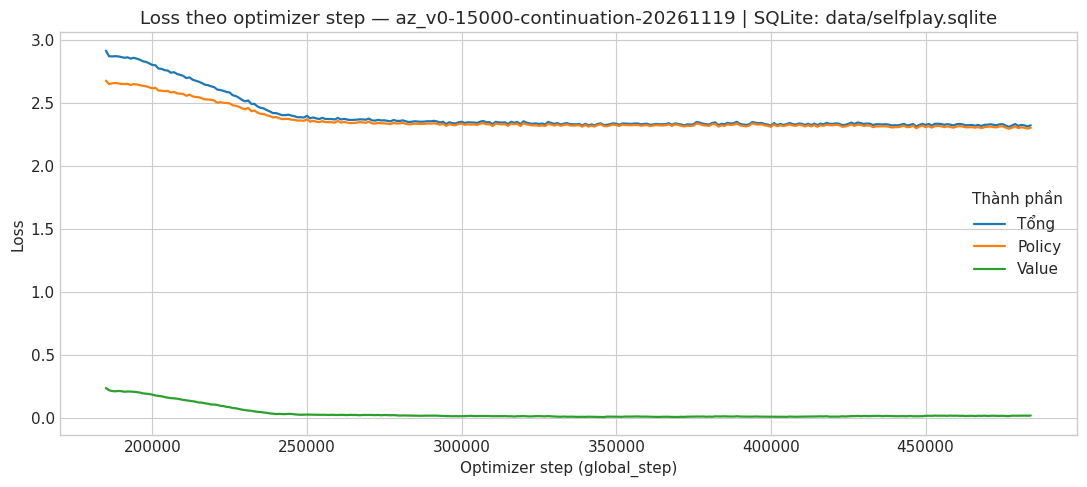

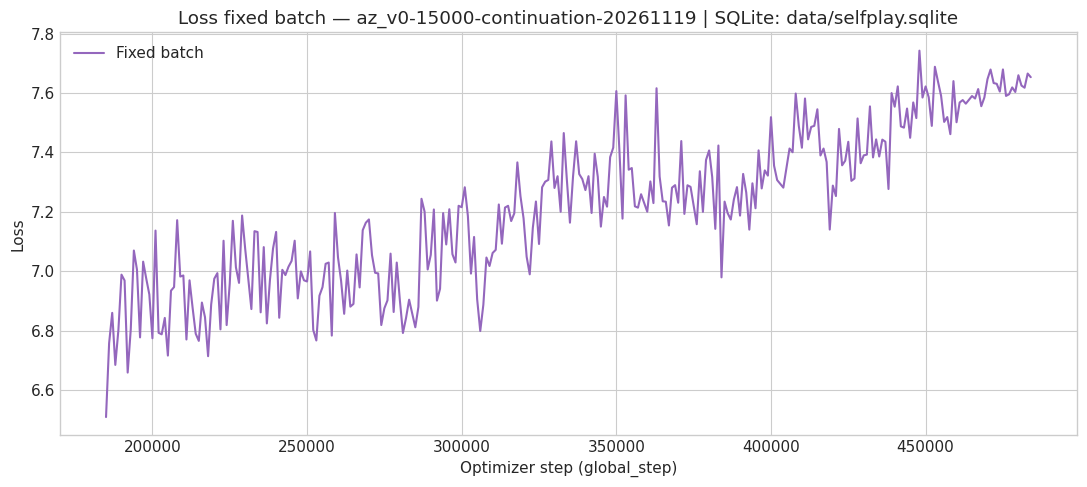

,iteration,global_step,m_games,m_loss,m_policy_loss,m_value_loss
0,201,185000,50,2.91326,2.67510,0.23816
297,500,484000,50,2.32103,2.30162,0.01941


Nguồn: SQLite: data/selfplay.sqlite. Run: az_v0-15000-continuation-20261119; 298 mốc metric duy nhất; không gộp run/nhánh.


In [5]:
details_path = ROOT / 'working_details.csv'
details = pd.read_csv(details_path, encoding='utf-8-sig') if details_path.is_file() else pd.DataFrame()
metric_source = f'SQLite: {DB_PATH.relative_to(ROOT).as_posix()}'
sql_has_loss = 'm_loss' in metric_rows.columns and metric_rows['m_loss'].notna().any()
if not sql_has_loss and not details.empty:
    csv_metrics = details.loc[details['Loại bản ghi'].eq('Metric từng iteration')].copy()
    csv_metrics = csv_metrics.rename(columns={'Mã run': 'run_id', 'Vòng huấn luyện': 'iteration',
        'Bước tối ưu tích lũy theo checkpoint': 'global_step', 'Ván self-play bổ sung trong vòng': 'm_games',
        'Tổng loss': 'm_loss', 'Loss chính sách': 'm_policy_loss', 'Loss giá trị': 'm_value_loss',
        'Loss theo lô theo dõi cố định': 'm_loss_eval_on_fixed_batch'})
    numeric_cols = ['iteration', 'global_step', 'm_games', 'm_loss', 'm_policy_loss', 'm_value_loss', 'm_loss_eval_on_fixed_batch']
    for col in numeric_cols:
        csv_metrics[col] = pd.to_numeric(csv_metrics[col], errors='coerce')
    if not csv_metrics.empty:
        metric_rows = csv_metrics
        metric_source = 'working_details.csv — Metric từng iteration'
if not metric_rows.empty and 'm_loss' in metric_rows.columns and metric_rows['m_loss'].notna().any():
    available = metric_rows.loc[metric_rows['m_loss'].notna()].groupby('run_id').size().sort_values(ascending=False)
    selected_run = PREFERRED_RUN_ID if PREFERRED_RUN_ID in set(available.index) else available.index[0]
    curve = metric_rows.loc[metric_rows.run_id.eq(selected_run)].copy()
    curve = curve.sort_values(['global_step', 'iteration']).drop_duplicates(['run_id', 'global_step'], keep='last')
    fig, ax = plt.subplots(figsize=(11, 5))
    for col, label in [('m_loss', 'Tổng'), ('m_policy_loss', 'Policy'), ('m_value_loss', 'Value')]:
        if col in curve and curve[col].notna().any():
            ax.plot(curve['global_step'], curve[col], label=label, linewidth=1.6)
    ax.set(title=f'Loss theo optimizer step — {selected_run} | {metric_source}', xlabel='Optimizer step (global_step)', ylabel='Loss')
    ax.legend(title='Thành phần'); fig.tight_layout(); plt.show()
    if 'm_loss_eval_on_fixed_batch' in curve and curve['m_loss_eval_on_fixed_batch'].notna().any():
        fig, ax = plt.subplots(figsize=(11, 5))
        ax.plot(curve['global_step'], curve['m_loss_eval_on_fixed_batch'], color='tab:purple', label='Fixed batch')
        ax.set(title=f'Loss fixed batch — {selected_run} | {metric_source}', xlabel='Optimizer step (global_step)', ylabel='Loss')
        ax.legend(); fig.tight_layout(); plt.show()
    display(curve[['iteration', 'global_step', 'm_games', 'm_loss', 'm_policy_loss', 'm_value_loss']].iloc[[0, -1]])
    print(f'Nguồn: {metric_source}. Run: {selected_run}; {len(curve)} mốc metric duy nhất; không gộp run/nhánh.')
else:
    selected_run = None
    print(f'Không có loss metric thực trong SQLite hoặc working_details.csv. Nguồn SQLite: {DB_PATH}; CSV: {details_path}.')

## Games, iteration, bước tối ưu và checkpoints
Checkpoint file được đếm theo thư mục local nhưng không load/deserialize. Tên `latest`/generation không bảo đảm lineage có thể cộng dồn; đây là inventory chứ không phải số model độc lập. `games` trong từng metric là games của iteration, còn `games_unique` ở bảng trên là record game duy nhất của run được ghi trong SQLite.

Checkpoint weight files local: 40; manifest.json: 866


,Tệp,MiB
0,checkpoints/latest.pt,5.62
1,checkpoints/normal/az_normal_weights.pt,1.88
2,checkpoints/normal/generations/379bac97e0fe424...,8.79
3,checkpoints/normal/generations/491281229c16416...,8.79
4,checkpoints/normal/generations/7c43f06544a045b...,7.38
5,checkpoints/normal/generations/e42491b1bf2743d...,8.79
6,checkpoints/renju/az_renju_weights.pt,5.62
7,checkpoints/renju_10/generations/cad30ce271f24...,1.89
8,checkpoints/renju_50/generations/fc405ae67a344...,1.89
9,checkpoints/renju_500/generations/929a1180127e...,1.89


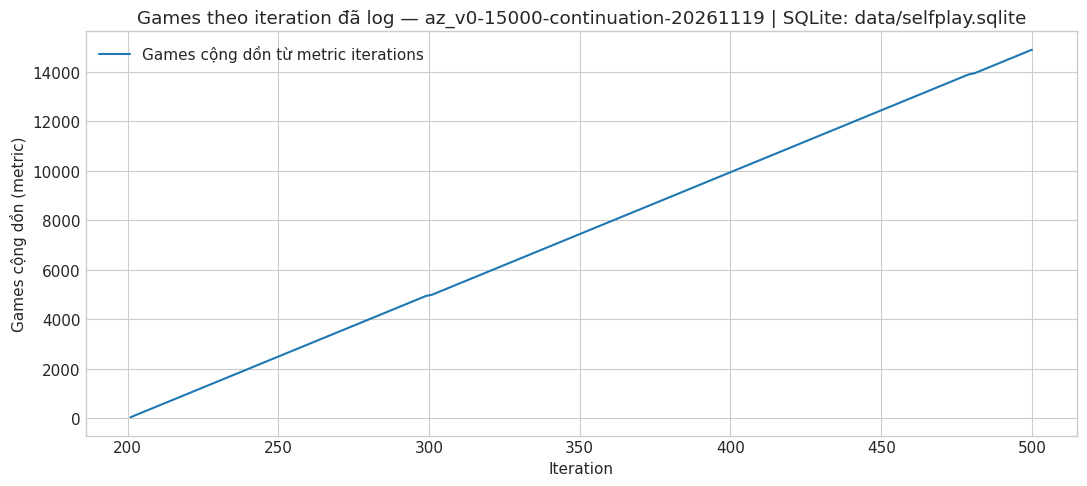

Nguồn: SQLite: data/selfplay.sqlite. Games ở đây là tổng games/iteration đã ghi; không thay thế distinct game_id.


In [6]:
ckpt_root = ROOT / 'checkpoints'
if ckpt_root.is_dir():
    checkpoint_files = sorted(p for p in ckpt_root.rglob('*') if p.is_file() and p.suffix.lower() in {'.pt', '.pth'})
    manifests = sorted(p for p in ckpt_root.rglob('manifest.json') if p.is_file())
    print(f'Checkpoint weight files local: {len(checkpoint_files)}; manifest.json: {len(manifests)}')
    display(pd.DataFrame([{'Tệp': p.relative_to(ROOT).as_posix(), 'MiB': round(p.stat().st_size / 2**20, 2)} for p in checkpoint_files]))
else:
    print('Thiếu thư mục checkpoints/ local (bị ignore trong Git). Không thể kiểm kê generation/checkpoint tại clone này.')
if selected_run is not None and not metric_rows.empty:
    plot_games = metric_rows.loc[metric_rows.run_id.eq(selected_run)].sort_values('iteration').drop_duplicates('iteration')
    if 'm_games' in plot_games and plot_games['m_games'].notna().any():
        plot_games['games_cumulative_logged'] = plot_games['m_games'].fillna(0).cumsum()
        fig, ax = plt.subplots(figsize=(11, 5))
        ax.plot(plot_games['iteration'], plot_games['games_cumulative_logged'], label='Games cộng dồn từ metric iterations')
        ax.set(title=f'Games theo iteration đã log — {selected_run} | {metric_source}', xlabel='Iteration', ylabel='Games cộng dồn (metric)')
        ax.legend(); fig.tight_layout(); plt.show()
        print(f'Nguồn: {metric_source}. Games ở đây là tổng games/iteration đã ghi; không thay thế distinct game_id.')
else:
    print('Không có run metric được chọn để vẽ số games theo iteration.')

`experiment_results.csv` là tổng hợp lịch sử; các hàng trong `working_details.csv` cung cấp metric theo iteration và được dùng làm fallback khi SQLite thiếu loss. Chỉ đối chiếu cùng `Mã run`/loại bản ghi; không cộng các hàng/mốc 40k, 50k, 60k như các run độc lập vì parent/branch có thể chồng lấp.

In [7]:
csv_path = ROOT / 'experiment_results.csv'
if csv_path.is_file():
    exp = pd.read_csv(csv_path, encoding='utf-8-sig')
    if 'Nhóm thí nghiệm' in exp.columns:
        display(exp.loc[exp['Nhóm thí nghiệm'].astype(str).str.contains('Self-play|huấn luyện|training', case=False, na=False),
                     [c for c in ['Mã thí nghiệm', 'Tên thí nghiệm', 'Phân loại bằng chứng', 'Chỉ số', 'Giá trị đầu ghi nhận', 'Giá trị cuối ghi nhận', 'Đơn vị', 'Số ván self-play bổ sung của nhánh', 'Ván lũy kế danh nghĩa theo nhãn checkpoint', 'Nguồn SQLite local', 'Nguồn trong Git', 'Ghi chú'] if c in exp.columns]].drop_duplicates())
    else:
        print('CSV không có cột phân loại để lọc; xem các cột:', exp.columns.tolist())
else:
    print('Thiếu experiment_results.csv trong clone hiện tại.')
detail_path = ROOT / 'working_details.csv'
if detail_path.is_file():
    details = pd.read_csv(detail_path, encoding='utf-8-sig')
    print(f'working_details.csv: {len(details)} dòng; lọc theo Mã run và Loại bản ghi thực tế.')
    detail_run = selected_run if selected_run is not None and selected_run in set(details['Mã run'].dropna()) else (PREFERRED_RUN_ID if PREFERRED_RUN_ID in set(details['Mã run'].dropna()) else None)
    if detail_run:
        selected_details = details.loc[details['Mã run'].eq(detail_run)]
        total_games = selected_details.loc[selected_details['Loại bản ghi'].eq('Tổng hợp ván theo run')]
        detail_metrics = selected_details.loc[selected_details['Loại bản ghi'].eq('Metric từng iteration')]
        if not total_games.empty:
            display(total_games[['Mã run', 'Trạng thái thống kê', 'Ván self-play ghi nhận trong run', 'Nguồn SQLite local', 'Nhóm nhận diện trùng']])
        if not detail_metrics.empty:
            display(detail_metrics.iloc[[0, -1]][['Vòng huấn luyện', 'Bước tối ưu tích lũy theo checkpoint', 'Ván self-play bổ sung trong vòng', 'Loss chính sách', 'Loss giá trị', 'Tổng loss', 'Loss theo lô theo dõi cố định', 'Trạng thái thống kê']])
    else:
        print('Không tìm thấy run đã chọn trong working_details.csv; không gộp hàng khác run.')
else:
    print('working_details.csv không có trong clone.')

,Mã thí nghiệm,Tên thí nghiệm,Phân loại bằng chứng,Chỉ số,Giá trị đầu ghi nhận,Giá trị cuối ghi nhận,Đơn vị,Ván lũy kế danh nghĩa theo nhãn checkpoint,Nguồn SQLite local,Nguồn trong Git,Ghi chú
0,normal_1000_20261028,Huấn luyện self-play Normal 1.000 ván,Lịch sử,Số vòng huấn luyện,NaN,NaN,vòng,NaN,data/selfplay.sqlite (bản nhập lịch sử; không ...,report/report.md mục 5.1; docs/report.md mục 6,Không cộng ván lặp trên các dòng metric; log g...
1,normal_1000_20261028,Huấn luyện self-play Normal 1.000 ván,Lịch sử,Số ván mỗi vòng,NaN,NaN,ván/vòng,NaN,data/selfplay.sqlite (bản nhập lịch sử; không ...,report/report.md mục 5.1; docs/report.md mục 6,Không cộng ván lặp trên các dòng metric; log g...
2,normal_1000_20261028,Huấn luyện self-play Normal 1.000 ván,Lịch sử,Số bước tối ưu,NaN,4000.00000,bước,NaN,data/selfplay.sqlite (bản nhập lịch sử; không ...,report/report.md mục 5.1; docs/report.md mục 6,Không cộng ván lặp trên các dòng metric; log g...
3,normal_1000_20261028,Huấn luyện self-play Normal 1.000 ván,Lịch sử,Kích thước bộ nhớ phát lại,2005.00000,30452.00000,mẫu,NaN,data/selfplay.sqlite (bản nhập lịch sử; không ...,report/report.md mục 5.1; docs/report.md mục 6,Không cộng ván lặp trên các dòng metric; log g...
4,normal_1000_20261028,Huấn luyện self-play Normal 1.000 ván,Lịch sử,Tổng loss,5.19370,4.09124,loss,NaN,data/selfplay.sqlite (bản nhập lịch sử; không ...,report/report.md mục 5.1; docs/report.md mục 6,Không cộng ván lặp trên các dòng metric; log g...
5,normal_1000_20261028,Huấn luyện self-play Normal 1.000 ván,Lịch sử,Loss chính sách,4.79342,3.76979,loss,NaN,data/selfplay.sqlite (bản nhập lịch sử; không ...,report/report.md mục 5.1; docs/report.md mục 6,Không cộng ván lặp trên các dòng metric; log g...
6,normal_1000_20261028,Huấn luyện self-play Normal 1.000 ván,Lịch sử,Loss giá trị,0.40028,0.32145,loss,NaN,data/selfplay.sqlite (bản nhập lịch sử; không ...,report/report.md mục 5.1; docs/report.md mục 6,Không cộng ván lặp trên các dòng metric; log g...
7,normal_1000_20261028,Huấn luyện self-play Normal 1.000 ván,Lịch sử,Loss theo lô theo dõi cố định,5.05494,5.14099,loss,NaN,data/selfplay.sqlite (bản nhập lịch sử; không ...,report/report.md mục 5.1; docs/report.md mục 6,Không cộng ván lặp trên các dòng metric; log g...
8,normal_1000_20261028,Huấn luyện self-play Normal 1.000 ván,Lịch sử,Độ dài trung bình mỗi ván,40.10000,23.10000,nước/ván,NaN,data/selfplay.sqlite (bản nhập lịch sử; không ...,report/report.md mục 5.1; docs/report.md mục 6,Không cộng ván lặp trên các dòng metric; log g...
9,normal_40k,Mốc huấn luyện Normal 40k,Lịch sử,NaN,NaN,NaN,NaN,40000.0,data/normal.sqlite (không theo dõi trong Git),docs/analysis/50k-quality-validation.md,40k là parent 25k + 15.000 ván; 50k là parent ...


working_details.csv: 3565 dòng; lọc theo Mã run và Loại bản ghi thực tế.


,Mã run,Trạng thái thống kê,Ván self-play ghi nhận trong run,Nguồn SQLite local,Nhóm nhận diện trùng
461,az_v0-15000-continuation-20261119,Chưa xác minh không trùng; không cộng chéo run,15000.0,data/selfplay.sqlite,NaN


,Vòng huấn luyện,Bước tối ưu tích lũy theo checkpoint,Ván self-play bổ sung trong vòng,Loss chính sách,Loss giá trị,Tổng loss,Loss theo lô theo dõi cố định,Trạng thái thống kê
462,201.0,185000.0,50.0,2.67510,0.23816,2.91326,6.50930,Chưa xác minh không trùng; không cộng chéo run
777,500.0,484000.0,50.0,2.30162,0.01941,2.32103,7.65346,Chưa xác minh không trùng; không cộng chéo run


## Nhận xét và điều kiện tái lập
* Iteration/loss lấy từ metric thực trong SQLite, hoặc `working_details.csv` theo cùng run nếu SQLite thiếu loss; khoảng metric vắng không được nội suy hay mặc định là thiếu optimizer update. Chỉ DB cho phép đếm `game_id` duy nhất; fallback CSV báo games/iteration đã ghi, không khẳng định count unique.
* `SPEC.md` mô tả pipeline: self-play tạo một sample mỗi vị trí MCTS, replay là ring buffer, training tối ưu policy cross-entropy mềm + value MSE; checkpoints/replay lưu riêng. Nhiều lần dùng mẫu replay không tương đương số ví dụ độc lập.
* `docs/analysis/training-data-audit.md` ghi nhận trong hiện vật lúc kiểm toán: run Normal continuation 15.000 game/151.893 moves; 298 metric rows cho iteration 201–500, thiếu 300 và 480; global step cuối 484.000. Báo cáo cũng nêu fixed-batch loss không phải holdout, games/moves/log/checkpoint không phải một commit đồng nhất và không cộng mốc chồng lấp. Những con số này là nội dung audit, không được khẳng định là tình trạng local hiện nay nếu DB không xác nhận.
* Cần `data/selfplay.sqlite` hoặc `data/normal.sqlite` để xem trajectory games/checkpoints trong DB; `data/` và `checkpoints/` bị Git ignore. Clone sạch vẫn có thể vẽ loss từ metric iteration tracked trong `working_details.csv`; checkpoint/replay và log raw có thể thiếu. Thiếu SQLite thì notebook không tạo DB, và chỉ dùng CSV làm fallback metric.
* Chỉ đọc DB bằng URI `mode=ro`; không tải `.pt` vì serialized checkpoint chỉ nên mở khi đáng tin cậy. Đồ thị loss mô tả quá trình tối ưu trên dữ liệu self-play, không đo playing strength. Kết luận sức chơi cần tournament matched, provenance, checkpoint identity và uncertainty như `SPEC.md` yêu cầu.